# RQ2 on Test Case A (ADR 1b): how much nonlinearity does the LDNet reconstructor need?

This notebook runs **Test Case A only** of `RQ2/RQ2_protocol.md`. The problem is the Diffusion-Reaction equation of the original Test Case 1b (Section 3.1.3 of the Supplementary Information):

$$
\begin{cases}
\frac{\partial z(x,t)}{\partial t} - \mu_1 \frac{\partial^2 z(x,t)}{\partial x^2} + \mu_3 z(x,t) = A(t) \cos(\pi x - P(t)), & x \in (-1,1), t\in (0,T], \\
z(-1,t) = z(1,t) & t\in (0,T], \\
z(x,0)= 0 & x \in (-1,1),
\end{cases}
$$

with $\mu_1 = 0.05$ and $\mu_3 = 0.02$. The LDNet predicts the space-time dynamics of $z(x,t)$ for a generic input $\mathbf{u}(t) = (A(t), P(t))$.

## Experiment

An LDNet is $\mathcal{NN}_{\mathrm{dyn}}$ (latent dynamics, Forward Euler, $\mathbf{s}(0)=0$) followed by a **reconstructor**. Only the reconstructor changes between the variants of the protocol (Sec. 4). Data, splits, normalisation, $\mathcal{NN}_{\mathrm{dyn}}$ (10-10-$d_s$), loss (MSE + $10^{-5}$ Tikhonov on the weights) and optimizer (50 Adam + 150 BFGS epochs) are the same everywhere. The linear variants add the mean field $\bar y(x)$ (mean of the training fields) and use the orthonormal Fourier basis $\varphi_k \in \{1/\sqrt2, \cos\pi x, \sin\pi x, \cos2\pi x, \sin2\pi x, \dots\}$, the basis for case A.

| Variant | Reconstructor | Trainable |
|---|---|---|
| L0 | $\mathcal{NN}_{\mathrm{rec}}(\mathbf{s},x)$, the original MLP 7-7-1 | MLP |
| L1 | $\bar y+\sum_{k=1}^{d_s}s_k\varphi_k$ | none |
| L2 | $\bar y+\sum_{k=1}^{K}(W\mathbf{s}+\mathbf{b})_k\varphi_k$ | $W,\mathbf{b}$ |
| L3 | $\bar y+\sum_{k=1}^{K}g_\theta(\mathbf{s})_k\varphi_k$ | $g_\theta$ |

Two training regimes (Sec. 5):
- **R1, frozen latents**: the L0 run with the same $(d_s,\text{seed})$ provides $\mathbf{s}(t)$; only the new reconstructor is fitted on these latents.
- **R2, end-to-end**: $\mathcal{NN}_{\mathrm{dyn}}$ and the reconstructor are trained together from scratch.

Sweep (Sec. 7): $d_s \in \{1,2,3,5\}$, $K \in \{d_s,3,5,9,17,33,65\}$, R1 and R2, 3 seeds. L1 has $K=d_s$ and L0 has no $K$ (stored as `K = 0`). For L0, R1 and R2 coincide: L0 is trained once, end-to-end, and its latents are the input of R1.

Not included: the L2+link variant (the output transform exists only in case B) and the "best size" sweep of $g_\theta$ (its width matches the parameter count of the L0 reconstructor).

## How to use

1. Run the **Setup**, **Experiment configuration** and **Helpers** cells (they are cheap: after a kernel restart run only these, then any analysis cell).
2. Run the variant sections in order. Each one trains its sweep, then draws its boxplots and trend plots. R1 of L1-L3 re-uses the latents saved by the L0 section.
3. The **final comparison** only reads results.

Time on a MacBook Pro M5 Pro (measured): about one hour for the whole sweep: L0 ~13 s per run, R2 runs of L1-L3 4-7 s, R1 runs under 4 s.

Everything is stored in `results/`, so more analyses never require re-training:
- `runs.csv`, `predictions.csv`, `modes.csv`: one row per run / test prediction / Fourier mode (columns in the *Metrics* cell);
- `weights/`: trained parameters of every run, a run can be rebuilt without re-training (`predict_test`);
- `latents/`: the L0 latents used by R1;
- `meta.json`: library versions, git hash of the first session and the training settings.

A sweep cell skips the runs already in `runs.csv`: it can be interrupted and resumed, and re-running the whole notebook only re-draws the plots. To investigate further, add cells that read the tables with `load('runs')`, `load('predictions')`, `load('modes')`.

**Reproducibility.** Every run calls `set_seed(seed)` (NumPy and TensorFlow) before any network is created, TensorFlow runs in deterministic mode on the CPU in float64, and L0 with seed 0 and $d_s=2$ is the original notebook: the L0 section checks that it reproduces the metrics of the original.

## Setup

In [23]:
# import modules
import contextlib
import io
import json
import pathlib
import subprocess
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats
import tensorflow as tf

# We configure TensorFlow to work in double precision
tf.keras.backend.set_floatx('float64')

# Double precision must run on the CPU here: the Apple Metal GPU plugin only registers
# single-precision kernels (e.g. ResourceApplyAdam with T=DT_DOUBLE is missing).
# We first try to hide the GPU; if the kernel already initialized it (e.g. this cell is
# re-run in an old session), we fall back to creating all model variables on /CPU:0.
try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass  # devices already initialized: fall back to the CPU device scope below
if tf.config.get_visible_devices('GPU'):
    print('GPU already initialized -> model variables will be created on /CPU:0.')
    cpu_device = lambda: tf.device('/CPU:0')
else:
    print('Running on CPU (float64).')
    cpu_device = contextlib.nullcontext

# Reproducibility: deterministic TensorFlow kernels. Random initialisers then require tf.random.set_seed,
# which setup_run() calls right before it creates the networks of a run.
tf.config.experimental.enable_op_determinism()

# Every run builds new tf.functions: this silences the "tf.function retracing" warnings that this triggers.
tf.get_logger().setLevel('ERROR')

import utils
import optimization

# utils.py and optimization.py have been copied into this folder from src/ without modifications.
print('utils        ->', utils.__file__)
print('optimization ->', optimization.__file__)

Running on CPU (float64).
utils        -> /Users/giuliodonninelli/Dev/LDNets/RQ2/ADR-1b/utils.py
optimization -> /Users/giuliodonninelli/Dev/LDNets/RQ2/ADR-1b/optimization.py


### Problem setting

We define the name of the variables of the problem at hand.

In [24]:
problem = {
    'space': {
        'dimension' : 1
    },
    'input_parameters': [],
    'input_signals': [
        { 'name': 'amplitude' },
        { 'name': 'phase' }
    ],
    'output_fields': [
        { 'name': 'z' }
    ]
}

We define, for each variable, a lower and an upper bound to be used to normalize the data.

In [25]:
normalization = {
    'space': { 'min' : [-1], 'max' : [+1]},
    'time': { 'time_constant' : 2.3 },
    'input_signals': {
        'amplitude': { 'min':   0, 'max': 0.8},
        'phase'    : { 'min':  -4, 'max': 4 },
    },
    'output_fields': {
        'z': { 'min': -1, 'max': +1 }
    }
}

We define the time step size. The number of latent states $d_s$ is a factor of the sweep (next section).

In [26]:
dt = 5e-2

### Datasets

We load training, validation and testing data. Here, training, validation and test sets comprise $n_{\mathrm{samples}} = 100$ samples each.
We resample data points on a regular grid with $n_{\mathrm{times}} = 101$ time instants and $n_{\mathrm{points}} = 100$ space points.
By following the notation of the paper, we denote by $d = 1$ the spatial dimension, by $d_{\mathbf{u}} = 2$ the number of input parameters and by $d_{\mathbf{y}} = 1$ the number of output fields.

Each dataset is stored as a Python dictionary, with the following fields (shape is indicated in square brackets):
- `times` $[n_{\mathrm{times}}]$: time instants;
- `points` $[n_{\mathrm{points}}, d]$: space points;
- `points_full` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d]$: space points repeated for each sample and time instant;
- `inp_signals` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, d_{\mathbf{u}}]$: input signals for each sample and time instant;
- `out_fields` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d_{\mathbf{y}}]$: output fields for each sample, time instant and space point.

In [27]:
data_set_path = '../../data/ADR/data_1b.npy'
samples_train = np.arange(  0, 100)
samples_valid = np.arange(100, 200)
samples_tests = np.arange(200, 300)

dataset = np.load(data_set_path, allow_pickle = True)[()]
dataset_train = utils.ADR_create_dataset(dataset, samples_train)
dataset_valid = utils.ADR_create_dataset(dataset, samples_valid) 
dataset_tests = utils.ADR_create_dataset(dataset, samples_tests) 

# We re-sample the time transients with timestep dt and we rescale each variable between -1 and 1.
utils.process_dataset(dataset_train, problem, normalization, dt = dt)
utils.process_dataset(dataset_valid, problem, normalization, dt = dt)
utils.process_dataset(dataset_tests, problem, normalization, dt = dt)

## Experiment configuration

Sweep levels of the protocol (Sec. 7) and training settings, identical for every variant and regime (those of the original notebook). Change `SEEDS`, `D_S` or `K_LEVELS` to run a subset (or more): results already in `results/` are kept and the missing runs are added. The training settings cannot change inside one results folder (a guard checks it against `meta.json`): use another `OUT` for that.

In [28]:
# ---- Sweep (protocol Sec. 7) ----
SEEDS = [0, 1, 2]                    # seed 0 is the seed of the original notebook
D_S = [1, 2, 3, 5]                   # number of latent states d_s
K_LEVELS = [3, 5, 9, 17, 33, 65]     # number of modes K (every d_s also adds K = d_s)

def K_for(d_s):
    return sorted({d_s, *K_LEVELS})

# ---- Training: identical for every variant and regime ----
EPOCHS_ADAM, EPOCHS_BFGS, LR_ADAM, ALPHA_REG = 50, 150, 1e-2, 1e-5

# ---- Results folder ----
OUT = pathlib.Path('results')
(OUT / 'weights').mkdir(parents = True, exist_ok = True)
(OUT / 'latents').mkdir(exist_ok = True)

# The results of all the sessions must come from the same training settings (and the first session is recorded)
training = dict(epochs_adam = EPOCHS_ADAM, epochs_bfgs = EPOCHS_BFGS, lr_adam = LR_ADAM, alpha_reg = ALPHA_REG)
if (OUT / 'meta.json').exists():
    assert json.loads((OUT / 'meta.json').read_text())['training'] == training, f'{OUT}/ holds results with other training settings: use another OUT'
else:
    git = subprocess.run('git rev-parse --short HEAD', shell = True, capture_output = True, text = True).stdout.strip()
    (OUT / 'meta.json').write_text(json.dumps(dict(tensorflow = tf.__version__, numpy = np.__version__, scipy = scipy.__version__,
                                                   pandas = pd.__version__, git = git, training = training), indent = 2))

## Helpers

### Fixed ingredients

Everything that depends on data is computed from the **training set only**: the mean field $\bar y(x)$ and (for the metrics) the Fourier basis, orthonormalised on the grid with the discrete $L^2$ inner product $\langle f,g\rangle_h = h\sum_i f(x_i)g(x_i)$. The solution of this problem is a combination of $\cos\pi x$ and $\sin\pi x$ only, so the first three Fourier functions already span it exactly.

In [29]:
SPLITS = {'train': dataset_train, 'valid': dataset_valid, 'test': dataset_tests}
denorm = lambda a: np.asarray(utils.denormalize_output(a, problem, normalization))
REF = {s: denorm(d['out_fields']) for s, d in SPLITS.items()}     # FOM fields [samples, times, points, 1]

x = dataset_train['points'][:, 0]                                 # [P] uniform periodic grid
X = tf.constant(dataset_train['points'])                          # [P, 1] the same grid, as network input
P, h = len(x), x[1] - x[0]

def fourier_basis(K):
    '''First K functions of {1/sqrt(2), cos(pi x), sin(pi x), cos(2 pi x), sin(2 pi x), ...}: [P, K].'''
    cols, k = [np.full_like(x, 1 / np.sqrt(2))], 1
    while len(cols) < K:
        cols.append(np.cos(k * np.pi * x))
        if len(cols) < K:
            cols.append(np.sin(k * np.pi * x))
        k += 1
    return np.stack(cols, axis = 1)

PHI = fourier_basis(P - 1)                                        # [P, P - 1]: all the admissible modes; first K columns = K modes
assert np.allclose(PHI.T @ PHI * h, np.eye(PHI.shape[1])), 'the basis is not orthonormal for <f, g>_h'

y_bar_n = dataset_train['out_fields'].numpy().mean(axis = (0, 1))[:, 0]   # mean field [P] (normalized units)
y_bar = denorm(y_bar_n[None, None, :, None])[0, 0, :, 0]                  # the same in physical units

### Networks and latent dynamics

`evolve` and `weights_reg` are those of the original notebook. `decode` is the linear synthesis $\bar y(x)+\sum_k c_k\,\mathrm{basis}_k(x)$ shared by L1-L3. $g_\theta$ is a tanh MLP with two hidden layers, like $\mathcal{NN}_{\mathrm{dyn}}$ and $\mathcal{NN}_{\mathrm{rec}}$; `matched_width` gives the largest width for which the reconstructor has at most as many parameters as the L0 one ($7d_s+78$, i.e. 92 for $d_s=2$), with a minimum of 1 (for large $K$ the output layer alone exceeds that budget: see `rec_params` in the results).

In [30]:
def set_seed(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

def mlp(n_in, width, n_out, lead = ()):
    '''tanh MLP with two hidden layers. `lead`: input axes before the feature axis (Keras checks the input rank).'''
    return tf.keras.Sequential([
        tf.keras.layers.Dense(width, activation = tf.nn.tanh, input_shape = (*lead, n_in)),
        tf.keras.layers.Dense(width, activation = tf.nn.tanh),
        tf.keras.layers.Dense(n_out)])

def mlp_params(n_in, width, n_out):
    return (n_in + 1) * width + (width + 1) * width + (width + 1) * n_out

def l0_params(d_s):
    return mlp_params(d_s + 1, 7, 1)                              # NNrec of the original notebook: 7-7-1 on (s, x)

def matched_width(budget, n_params):
    '''Largest width >= 1 with n_params(width) <= budget.'''
    width = 1
    while n_params(width + 1) <= budget:
        width += 1
    return width

def make_dyn(d_s):
    return mlp(d_s + len(problem['input_parameters']) + len(problem['input_signals']), 10, d_s)

def decode(coeffs, basis):
    '''y_bar(x) + sum_k coeffs_k * basis_k(x):  coeffs [S, T, K], basis [P, K]  ->  [S, T, P, 1].'''
    return (tf.matmul(coeffs, basis, transpose_b = True) + y_bar_n)[..., tf.newaxis]

def evolve(NNdyn, d_s, dataset):
    '''Latent states [S, T, d_s]: Forward Euler from s(0) = 0 (evolve_dynamics of the original notebook).'''
    state = tf.zeros((dataset['num_samples'], d_s), dtype = tf.float64)
    state_history = tf.TensorArray(tf.float64, size = dataset['num_times'])
    state_history = state_history.write(0, state)
    dt_ref = normalization['time']['time_constant']
    for i in tf.range(dataset['num_times'] - 1):
        state = state + dt/dt_ref * NNdyn(tf.concat([state, dataset['inp_signals'][:,i,:]], axis = -1))
        state_history = state_history.write(i + 1, state)
    return tf.transpose(state_history.stack(), perm=(1, 0, 2))

def weights_reg(NN):
    return sum([tf.reduce_mean(tf.square(lay.kernel)) for lay in NN.layers])/len(NN.layers)

### Metrics (protocol Sec. 8) and result tables

Every run appends rows to three tables in `results/`, all keyed by `variant, regime, d_s, K, seed`:

| file | one row per | columns |
|---|---|---|
| `runs.csv` | run | `nrmse_{train,valid,test}`, `one_minus_rho_{train,valid,test}`, `eps_total_test`, `eps_proj_test`, `eff_ratio_test`, `rec_params`, `width`, `train_time_s`, `infer_time_s` |
| `predictions.csv` | test sample (= one prediction) of a run | `sample` (index in the test set), `nrmse`, `one_minus_rho`, `eps_total`, `eps_proj`, `eff_ratio` |
| `modes.csv` | Fourier mode of a run | `mode`, `err_abs`, `ref_norm`, `err_rel` |

- **NRMSE** and **Pearson dissimilarity** $1-\rho$ are those of the original notebook, on the denormalized fields. The per-prediction NRMSE uses the range of the whole split, so the NRMSE of `runs.csv` is the root mean square of the per-prediction values.
- **Efficiency ratio**: $\varepsilon_{\mathrm{total}}=\|\hat y-y\|/\|y\|$ (norm over time and space), $\varepsilon_{\mathrm{proj}}(K)=\|(y-\bar y)-P_K(y-\bar y)\|/\|y\|$ with $P_K$ the projection on the first $K$ Fourier modes (the floor of Sec. 6 on the mean-subtracted field, since every variant adds $\bar y$), `eff_ratio` $=\varepsilon_{\mathrm{total}}/\varepsilon_{\mathrm{proj}}$. Empty for L0 (no $K$). Here the solution lies exactly in $\mathrm{span}\{\cos\pi x,\sin\pi x\}$: for $K\ge3$ the floor is at round-off level and the ratio is huge, i.e. the error is not due to the representation.
- **Per-mode error**: $c_k(t)=\langle y(\cdot,t)-\bar y,\varphi_k\rangle_h$ for the FOM and $\hat c_k(t)$ for the prediction (for every variant, also L0); `err_abs` $=\|\hat c_k-c_k\|$ and `ref_norm` $=\|c_k\|$ over all test samples and times, `err_rel` $=\varepsilon_k$ is their ratio. Modes $k\le K$ (L0: $k\le\max K$ of the sweep). The FOM has almost no energy in the modes beyond $\cos\pi x,\sin\pi x$: use `err_abs` there.
- **Cost**: `rec_params` (parameters of the reconstructor) and `width` (hidden width of its MLPs, 0 if none), `train_time_s` (the whole optimization, tracing included: in R1 only the fit of the reconstructor, the training of L0 is its own row), `infer_time_s` (reconstructor on the test latents, best of 3).

In [31]:
RUN_KEYS = ['variant', 'regime', 'd_s', 'K', 'seed']
EXTRA_KEYS = {'runs': [], 'predictions': ['sample'], 'modes': ['mode']}

def run_id(variant, regime, d_s, K, seed):
    return f'{variant}_{regime}_ds{d_s}_K{K}_s{seed}'

def append(name, df):
    path = OUT / f'{name}.csv'
    df.to_csv(path, mode = 'a', header = not path.exists(), index = False)

def load(name):
    '''Results table `name` ('runs', 'predictions' or 'modes'). A run interrupted while saving can leave duplicated rows: the last ones are kept.'''
    return pd.read_csv(OUT / f'{name}.csv').drop_duplicates(subset = RUN_KEYS + EXTRA_KEYS[name], keep = 'last')

def with_key(df, key):
    for i, (k, v) in enumerate(key.items()):
        df.insert(i, k, v)
    return df

def nrmse_rho(app, ref):
    '''Aggregated metrics of the original notebook.'''
    nrmse = np.sqrt(np.mean(np.square(app - ref))) / (np.max(ref) - np.min(ref))
    return nrmse, 1.0 - scipy.stats.pearsonr(app.reshape(-1), ref.reshape(-1))[0]

def rel_norm(a, ref):
    '''||a_i|| / ||ref_i|| for every sample i (norm over time and space).'''
    return np.linalg.norm(a.reshape(len(a), -1), axis = 1) / np.linalg.norm(ref.reshape(len(ref), -1), axis = 1)

def proj_residual(ref, K):
    '''(y - y_bar) - P_K (y - y_bar): the part of the field that K Fourier modes plus y_bar cannot represent.'''
    B = PHI[:, :K]
    yc = ref[..., 0] - y_bar
    return yc - (yc @ B * h) @ B.T

def prediction_table(app, ref, K):
    n = len(ref)
    eps_total = rel_norm(app - ref, ref)
    eps_proj = rel_norm(proj_residual(ref, K), ref) if K else np.full(n, np.nan)
    return pd.DataFrame(dict(
        sample = np.arange(n),
        nrmse = np.sqrt(np.mean(np.square(app - ref), axis = (1, 2, 3))) / (ref.max() - ref.min()),
        one_minus_rho = [1.0 - scipy.stats.pearsonr(a.reshape(-1), r.reshape(-1))[0] for a, r in zip(app, ref)],
        eps_total = eps_total, eps_proj = eps_proj, eff_ratio = eps_total / eps_proj))

def mode_table(app, ref, K):
    B = PHI[:, :(K or max(K_LEVELS))]                            # L0 (K = 0): modes up to the largest K of the sweep
    c_ref = (ref[..., 0] - y_bar) @ B * h                        # [S, T, K] coefficients of the FOM
    c_app = (app[..., 0] - y_bar) @ B * h                        # [S, T, K] coefficients of the prediction
    err_abs = np.linalg.norm((c_app - c_ref).reshape(-1, B.shape[1]), axis = 0)
    ref_norm = np.linalg.norm(c_ref.reshape(-1, B.shape[1]), axis = 0)
    return pd.DataFrame(dict(mode = np.arange(1, B.shape[1] + 1), err_abs = err_abs, ref_norm = ref_norm, err_rel = err_abs / ref_norm))

### Reconstructors L0-L3

`build_Lx(d_s, K)` returns the reconstructor `rec(states)`, which maps the latent states `[samples, times, d_s]` to fields `[samples, times, points, 1]`, and the list of its trainable networks (they enter the regularisation and the trainable variables). `BUILD` is what `setup_run` uses to rebuild any run. $g_\theta$ is sized by `matched_width` to the parameter count of the L0 reconstructor.

In [32]:
def build_L0(d_s, K):                                                       # K is not used
    NNrec = mlp(d_s + 1, 7, 1, lead = (None, None))                         # the original MLP 7-7-1, inputs (s, x)
    def rec(states):
        S, T = tf.shape(states)[0], tf.shape(states)[1]
        s = tf.broadcast_to(states[:, :, None, :], [S, T, P, d_s])
        return NNrec(tf.concat([s, tf.broadcast_to(X, [S, T, P, 1])], axis = -1))
    return rec, [NNrec]

def build_L1(d_s, K):                                                       # K == d_s: no trainable parameter
    basis = tf.constant(PHI[:, :K])
    def rec(states):
        return decode(states, basis)
    return rec, []

def build_L2(d_s, K):
    affine = tf.keras.Sequential([tf.keras.layers.Dense(K, input_shape = (None, d_s))])     # c = W s + b
    basis = tf.constant(PHI[:, :K])
    def rec(states):
        return decode(affine(states), basis)
    return rec, [affine]

def build_L3(d_s, K):
    width = matched_width(l0_params(d_s), lambda w: mlp_params(d_s, w, K))
    g = mlp(d_s, width, K, lead = (None,))                                  # c = g(s)
    basis = tf.constant(PHI[:, :K])
    def rec(states):
        return decode(g(states), basis)
    return rec, [g]

BUILD = {'L0': build_L0, 'L1': build_L1, 'L2': build_L2, 'L3': build_L3}

### Runs

`setup_run` rebuilds every object of a run from its seed. `run_one` trains it (50 Adam + 150 BFGS epochs, the per-epoch log is silenced), evaluates it and appends its results to the tables. `sweep` runs the whole grid of a variant (seed by seed, so that an interrupted sweep still gives complete grids for the first seeds) and skips what is already in `runs.csv`.

In R1 the latents of the L0 run are frozen: no time integration is needed and only the reconstructor is trained (R1 of L1 has nothing to train: the fixed formula is just evaluated). In R2 `NNdyn` is created first in every run, as in the original notebook; R1 creates it too (unused), so that the reconstructor starts from the same initial weights in R1 and R2.

In [33]:
def setup_run(variant, regime, d_s, K, seed):
    '''Re-creates from the seed all the objects of a run: states_of(split), reconstructor, trained networks, reconstructor networks.'''
    set_seed(seed)
    with cpu_device():
        NNdyn = make_dyn(d_s)
        rec, rec_nets = BUILD[variant](d_s, K)
    if regime == 'R2':                                            # end-to-end: NNdyn is trained with the reconstructor
        def states_of(split):
            return evolve(NNdyn, d_s, SPLITS[split])
        return states_of, rec, [NNdyn] + rec_nets, rec_nets
    latents_file = OUT / 'latents' / f'L0_ds{d_s}_seed{seed}.npz'  # R1: frozen latents of the L0 run with the same (d_s, seed)
    if not latents_file.exists():
        raise FileNotFoundError(f'{latents_file} is missing: run the L0 section first (R1 re-uses its latents)')
    latents = dict(np.load(latents_file))
    def states_of(split):
        return tf.constant(latents[split])
    return states_of, rec, rec_nets, rec_nets

def seconds(f):
    t0 = time.perf_counter()
    f()
    return time.perf_counter() - t0

def run_one(variant, regime, d_s, K, seed):
    '''Trains (or just evaluates) one run and appends its results to the CSV files.'''
    key = dict(variant = variant, regime = regime, d_s = d_s, K = K, seed = seed)
    states_of, rec, nets, rec_nets = setup_run(**key)
    variables = [v for n in nets for v in n.variables]

    def mse(split):
        return tf.reduce_mean(tf.square(rec(states_of(split)) - SPLITS[split]['out_fields']))
    def loss():
        return mse('train') + ALPHA_REG * sum(weights_reg(n) for n in nets)
    def loss_valid():
        return mse('valid')

    t0 = time.time()
    if variables:                                                 # (R1 of L1 has no trainable parameter)
        with contextlib.redirect_stdout(io.StringIO()):           # silences the per-epoch log of optimization.py
            opt = optimization.OptimizationProblem(variables, loss, loss_valid)
            opt.optimize_keras(EPOCHS_ADAM, tf.keras.optimizers.Adam(learning_rate = LR_ADAM))
            opt.optimize_BFGS(EPOCHS_BFGS)
    train_time = time.time() - t0

    states = {s: states_of(s) for s in SPLITS}                    # [S, T, d_s]
    pred = {s: denorm(rec(states[s])) for s in SPLITS}            # [S, T, P, 1]
    ref, app = REF['test'], pred['test']

    row = dict(key, rec_params = sum(int(np.prod(v.shape)) for n in rec_nets for v in n.variables),
               width = max((l.units for n in rec_nets for l in n.layers[:-1]), default = 0),     # hidden width of the MLPs (0: none)
               train_time_s = train_time, infer_time_s = min(seconds(lambda: rec(states['test'])) for _ in range(3)))
    for s in SPLITS:
        row[f'nrmse_{s}'], row[f'one_minus_rho_{s}'] = nrmse_rho(pred[s], REF[s])
    eps_total = np.linalg.norm(app - ref) / np.linalg.norm(ref)
    eps_proj = np.linalg.norm(proj_residual(ref, K)) / np.linalg.norm(ref) if K else np.nan
    row.update(eps_total_test = eps_total, eps_proj_test = eps_proj, eff_ratio_test = eps_total / eps_proj)

    rid = run_id(**key)
    if variables:
        np.save(OUT / 'weights' / f'{rid}.npy', optimization.VariablesStitcher(variables).stitch().numpy())
    if variant == 'L0':                                           # the latents that R1 of the other variants needs
        np.savez(OUT / 'latents' / f'L0_ds{d_s}_seed{seed}.npz', **{s: states[s].numpy() for s in SPLITS})
    append('predictions', with_key(prediction_table(app, ref, K), key))
    append('modes', with_key(mode_table(app, ref, K), key))
    append('runs', pd.DataFrame([row]))                           # last: a run is done only when its row is in runs.csv
    print(f'{rid:24s} train {train_time:6.1f} s   test NRMSE {row["nrmse_test"]:.3e}')

def sweep(variant, regimes = ('R1', 'R2'), K_of = K_for):
    '''Runs the missing (seed, d_s, K, regime) of a variant; the finished ones (rows of runs.csv) are skipped.'''
    done = set()
    if (OUT / 'runs.csv').exists():
        runs = load('runs')
        done = set(zip(runs.variant, runs.regime, runs.d_s, runs.K, runs.seed))
    grid = [(variant, r, d, K, s) for s in SEEDS for d in D_S for K in K_of(d) for r in regimes]
    todo = [g for g in grid if g not in done]
    print(f'{variant}: {len(todo)} runs to do, {len(grid) - len(todo)} already done')
    for i, g in enumerate(todo, 1):
        print(f'[{i}/{len(todo)}]', end = ' ')
        run_one(*g)

def predict_test(variant, regime, d_s, K, seed):
    '''Test prediction of a stored run, rebuilt from its saved weights (no training).'''
    states_of, rec, nets, _ = setup_run(variant, regime, d_s, K, seed)
    variables = [v for n in nets for v in n.variables]
    if variables:
        optimization.VariablesStitcher(variables).update_variables(np.load(OUT / 'weights' / f'{run_id(variant, regime, d_s, K, seed)}.npy'))
    return denorm(rec(states_of('test')))

### Plots

For every variant: a boxplot over the seeds for each configuration (one panel per $d_s$; boxes ordered by $K$, colour = regime), and the trend of the median over the seeds (band: interquartile range) as the dimensionality varies.

In [62]:
REGIME_COLOR = {'R1': 'tab:orange', 'R2': 'tab:blue'}
LABEL = {'nrmse_test': 'test NRMSE', 'one_minus_rho_test': 'test 1 - rho'}

def boxplot_variant(variant, metric = 'nrmse_test'):
    '''Distribution over the seeds of `metric` for every configuration (K, regime), one panel per d_s.'''
    runs = load('runs')
    df = runs[runs.variant == variant]
    assert len(df), f'no results for {variant}: run its sweep first'
    d_values = sorted(df.d_s.unique())
    ncols = min(2, len(d_values))
    nrows = -(-len(d_values) // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize = (6.5 * ncols, 3.8 * nrows), squeeze = False, sharey = True)
    for ax, d_s in zip(axs.ravel(), d_values):
        sub = df[df.d_s == d_s]
        groups = sorted(sub.groupby(['K', 'regime']).groups)                        # [(K, regime), ...]
        bp = ax.boxplot([sub[(sub.K == K) & (sub.regime == r)][metric] for K, r in groups],
                        labels = [f"{K if K else '-'}\n{r}" for K, r in groups], patch_artist = True)
        for patch, (K, r) in zip(bp['boxes'], groups):
            patch.set_facecolor(REGIME_COLOR[r])
        ax.set(title = f'd_s = {d_s}', xlabel = 'K  /  regime')
        ax.grid(True, axis = 'y', alpha = 0.3)
    for ax in axs[:, 0]:
        ax.set_ylabel(LABEL.get(metric, metric))
    for ax in axs.ravel()[len(d_values):]:
        ax.axis('off')
    fig.suptitle(f'{variant}: {LABEL.get(metric, metric)} over the seeds')
    fig.tight_layout()
    plt.show()

def trend_variant(variant, metric = 'nrmse_test'):
    '''Median (line) and interquartile range (band) over the seeds of `metric` versus the dimensionality, one panel per regime.'''
    runs = load('runs')
    df = runs[runs.variant == variant]
    assert len(df), f'no results for {variant}: run its sweep first'
    x_col, hue = ('K', 'd_s') if variant in ('L2', 'L3') else ('d_s', None)   # L0, L1: dimensionality = d_s
    regimes = sorted(df.regime.unique())
    fig, axs = plt.subplots(1, len(regimes), figsize = (6 * len(regimes), 4), squeeze = False, sharey = True)
    for ax, regime in zip(axs[0], regimes):
        sub = df[df.regime == regime]
        for label, g in (sub.groupby(hue) if hue else [(None, sub)]):
            q = g.groupby(x_col)[metric].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(q.index, q[0.5], 'o-', label = f'd_s = {label}' if hue else None)
            ax.fill_between(q.index, q[0.25], q[0.75], alpha = 0.2)
        ticks = sorted(sub[x_col].unique())
        ax.set(title = f'{variant}, {regime}', xlabel = x_col, ylabel = LABEL.get(metric, metric))
        if hue:
            ax.set_xscale('log', base = 2)
            ax.legend()
        ax.set_xticks(ticks)
        ax.set_xticklabels(ticks)
        ax.set_xticks([], minor = True)
        ax.grid(True, which = 'both', alpha = 0.3)
    fig.tight_layout()
    plt.show()

## L0: original reconstructor $\mathcal{NN}_{\mathrm{rec}}(\mathbf{s},x)$

The MLP 7-7-1 of the original notebook (`build_L0`, 92 parameters for $d_s=2$), trained end-to-end together with $\mathcal{NN}_{\mathrm{dyn}}$. There is no $K$ (stored as `K = 0`), so the sweep is over $d_s$ only. R1 and R2 coincide for L0: this is the run that provides the latents used by R1 of L1-L3 (saved in `results/latents`).

In [35]:
sweep('L0', regimes = ('R2',), K_of = lambda d_s: [0])

L0: 12 runs to do, 0 already done
[1/12] 

2026-10-04 16:16:14.477348: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


L0_R2_ds1_K0_s0          train   13.4 s   test NRMSE 7.990e-02
[2/12] L0_R2_ds2_K0_s0          train   13.2 s   test NRMSE 2.440e-02
[3/12] L0_R2_ds3_K0_s0          train   14.0 s   test NRMSE 2.632e-02
[4/12] L0_R2_ds5_K0_s0          train   14.9 s   test NRMSE 2.650e-02
[5/12] L0_R2_ds1_K0_s1          train   13.3 s   test NRMSE 7.925e-02
[6/12] L0_R2_ds2_K0_s1          train   13.7 s   test NRMSE 2.396e-02
[7/12] L0_R2_ds3_K0_s1          train   13.8 s   test NRMSE 2.487e-02
[8/12] L0_R2_ds5_K0_s1          train   14.3 s   test NRMSE 1.963e-02
[9/12] L0_R2_ds1_K0_s2          train   12.9 s   test NRMSE 7.984e-02
[10/12] L0_R2_ds2_K0_s2          train   14.0 s   test NRMSE 2.183e-02
[11/12] L0_R2_ds3_K0_s2          train   13.5 s   test NRMSE 2.195e-02
[12/12] L0_R2_ds5_K0_s2          train   14.2 s   test NRMSE 2.264e-02


**Reproducibility gate** (protocol Sec. 11): L0 with seed 0 and $d_s=2$ is the original notebook, whose printed metrics it has to reproduce.

In [36]:
ORIGINAL = {'nrmse_train': 1.914e-02, 'nrmse_test': 2.440e-02, 'one_minus_rho_train': 7.859e-03, 'one_minus_rho_test': 1.052e-02}
gate = load('runs').query("variant == 'L0' and d_s == 2 and seed == 0")
if len(gate):
    for k, v in ORIGINAL.items():
        print(f'{k:20s} this run {gate.iloc[0][k]:.3e}   original notebook {v:.3e}')
    assert all(np.isclose(gate.iloc[0][k], v, rtol = 2e-3) for k, v in ORIGINAL.items()), 'L0 does not reproduce the original notebook'
    print('gate passed')
else:
    print('gate skipped: L0 with d_s = 2 and seed 0 is not in the results')

nrmse_train          this run 1.914e-02   original notebook 1.914e-02
nrmse_test           this run 2.440e-02   original notebook 2.440e-02
one_minus_rho_train  this run 7.859e-03   original notebook 7.859e-03
one_minus_rho_test   this run 1.052e-02   original notebook 1.052e-02
gate passed


### L0: comparison of the configurations

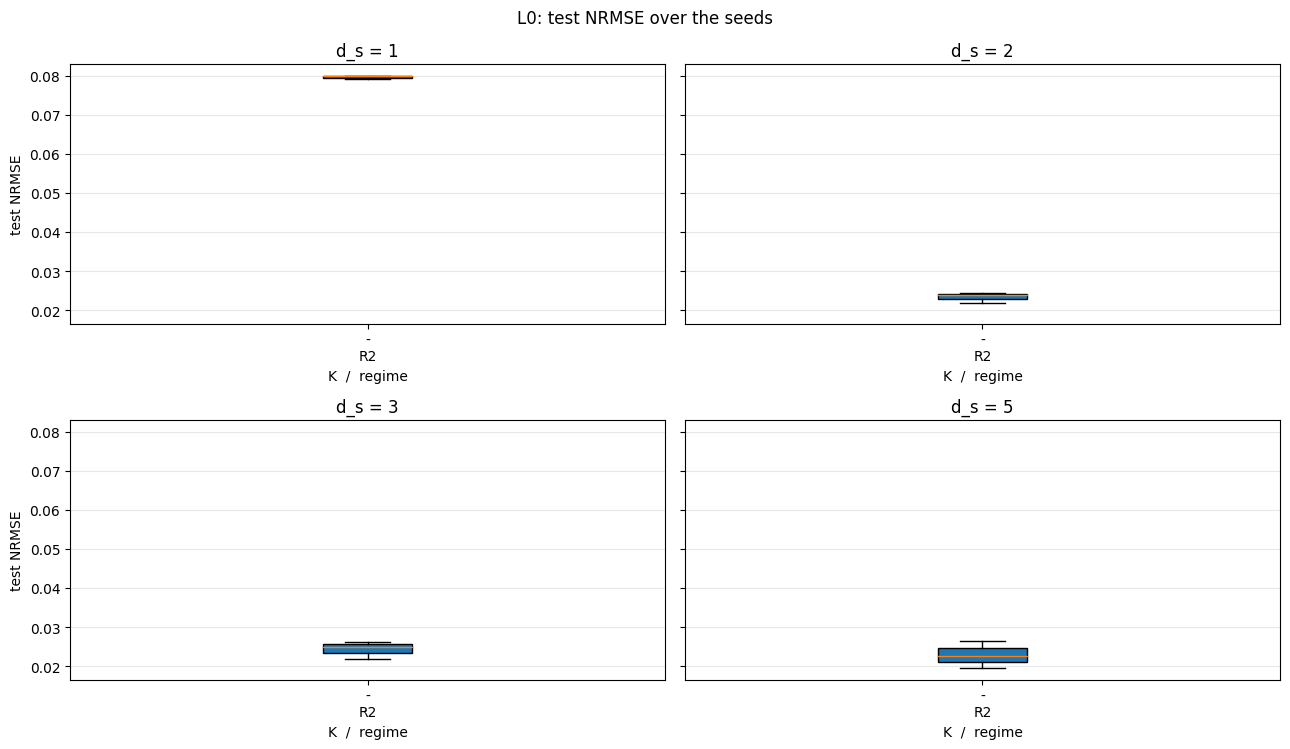

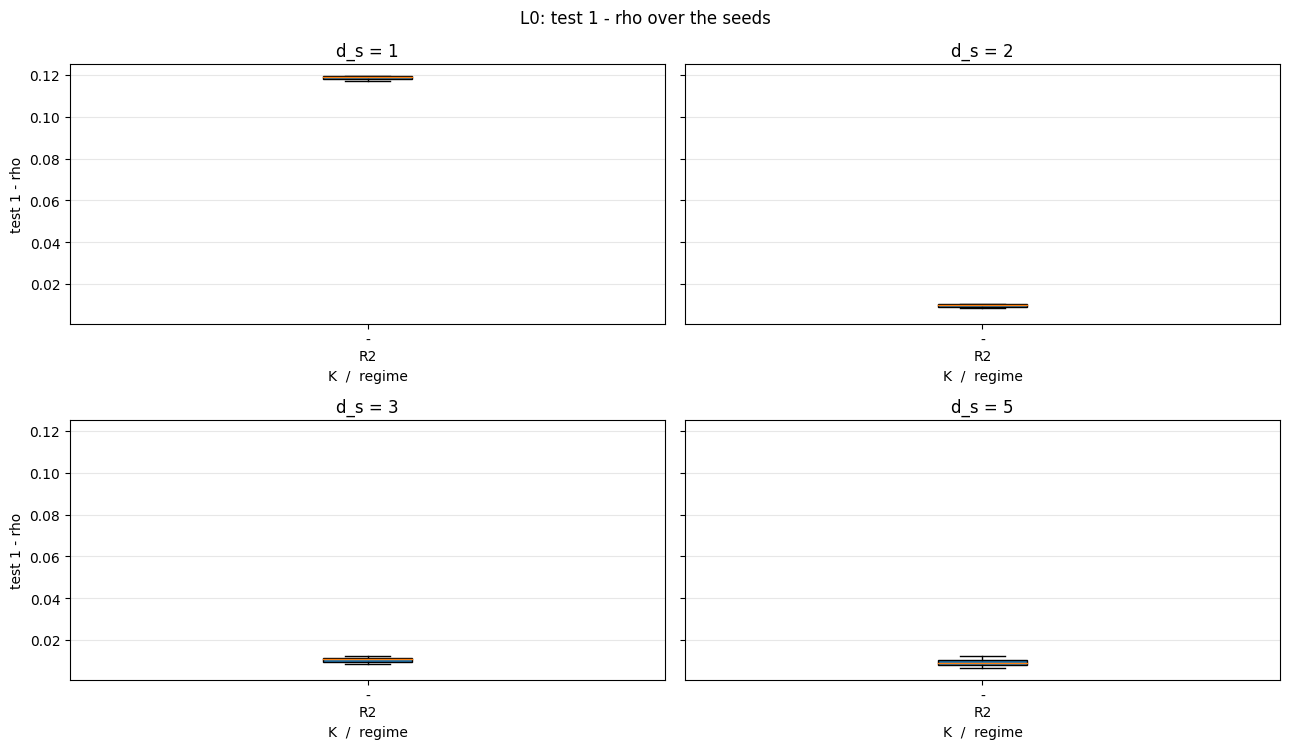

In [52]:
boxplot_variant('L0', 'nrmse_test')
boxplot_variant('L0', 'one_minus_rho_test')

### L0: trend with the dimensionality

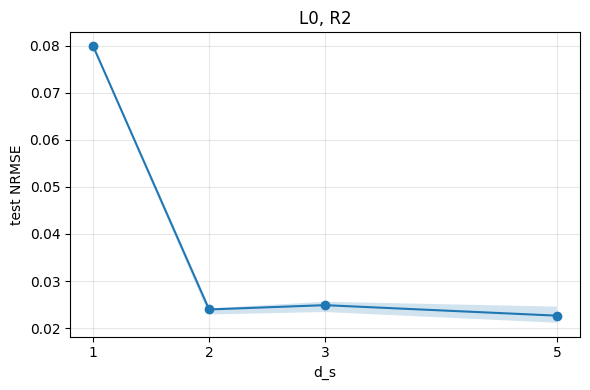

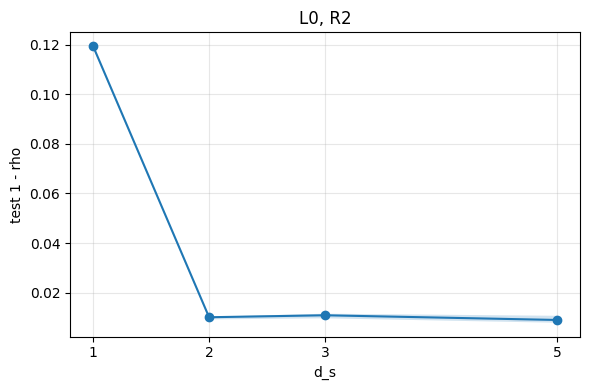

In [63]:
trend_variant('L0', 'nrmse_test')
trend_variant('L0', 'one_minus_rho_test')

## L1: fixed modes, $\bar y+\sum_{k=1}^{d_s}s_k\varphi_k$

The latent states are the coefficients of the first $d_s$ Fourier modes (`build_L1`, $K=d_s$): the reconstructor has **no trainable parameter**. In R2 only $\mathcal{NN}_{\mathrm{dyn}}$ is trained, which forces the latents to be modal. In R1 the fixed formula is just evaluated on the frozen L0 latents (nothing to fit), so R1 measures whether the latents of L0 are modal on their own.

In [39]:
sweep('L1', K_of = lambda d_s: [d_s])

L1: 24 runs to do, 0 already done
[1/24] L1_R1_ds1_K1_s0          train    0.0 s   test NRMSE 1.641e-01
[2/24] L1_R2_ds1_K1_s0          train    3.6 s   test NRMSE 1.449e-01
[3/24] L1_R1_ds2_K2_s0          train    0.0 s   test NRMSE 2.114e-01
[4/24] L1_R2_ds2_K2_s0          train    3.8 s   test NRMSE 1.130e-01
[5/24] L1_R1_ds3_K3_s0          train    0.0 s   test NRMSE 2.559e-01
[6/24] L1_R2_ds3_K3_s0          train    3.8 s   test NRMSE 2.848e-02
[7/24] L1_R1_ds5_K5_s0          train    0.0 s   test NRMSE 2.725e-01
[8/24] L1_R2_ds5_K5_s0          train    4.3 s   test NRMSE 2.776e-02
[9/24] L1_R1_ds1_K1_s1          train    0.0 s   test NRMSE 1.798e-01
[10/24] L1_R2_ds1_K1_s1          train    3.5 s   test NRMSE 1.449e-01
[11/24] L1_R1_ds2_K2_s1          train    0.0 s   test NRMSE 2.180e-01
[12/24] L1_R2_ds2_K2_s1          train    3.7 s   test NRMSE 1.131e-01
[13/24] L1_R1_ds3_K3_s1          train    0.0 s   test NRMSE 1.807e-01
[14/24] L1_R2_ds3_K3_s1          train    3.8 s   te

### L1: comparison of the configurations

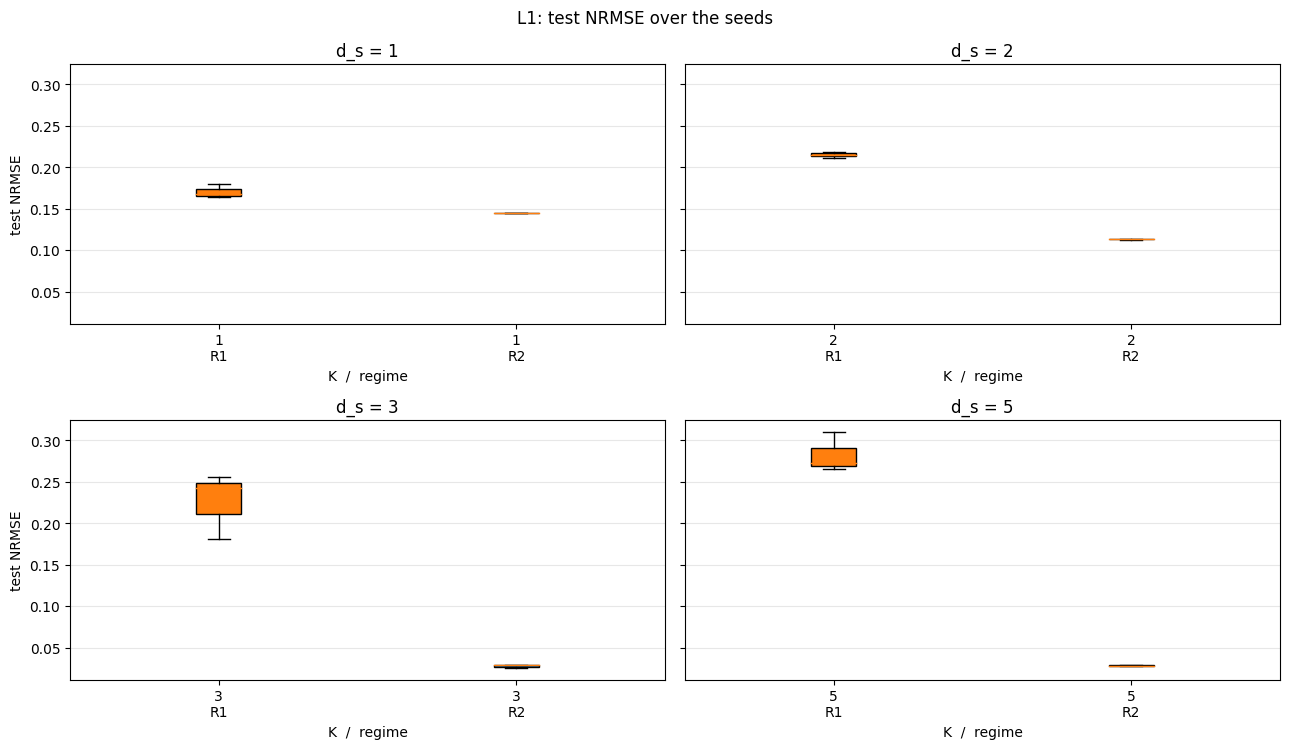

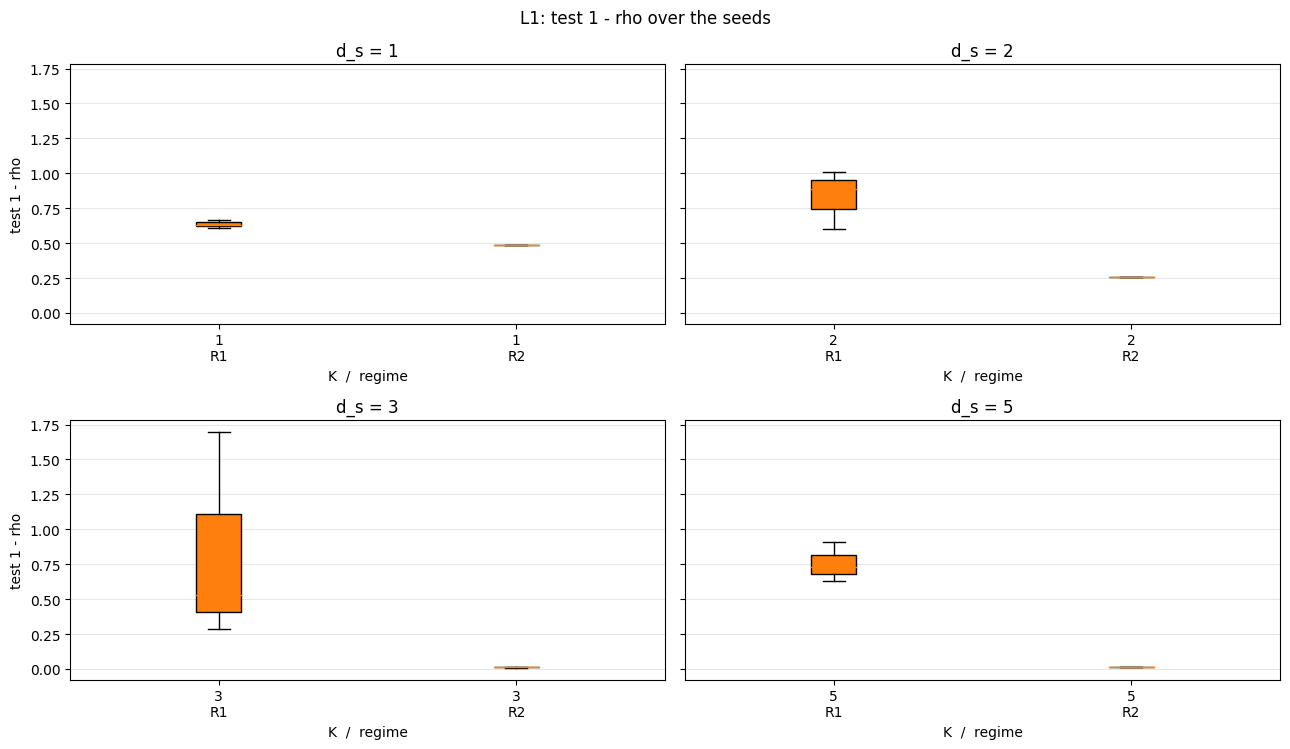

In [54]:
boxplot_variant('L1', 'nrmse_test')
boxplot_variant('L1', 'one_minus_rho_test')

### L1: trend with the dimensionality

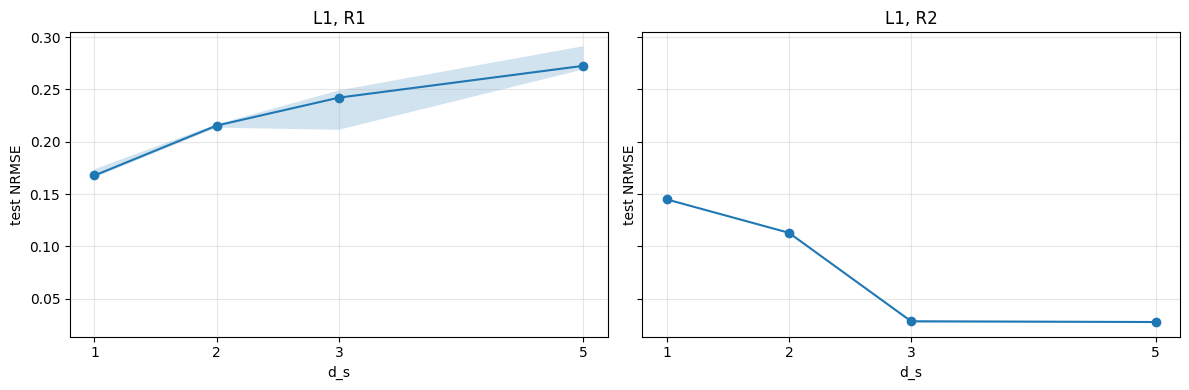

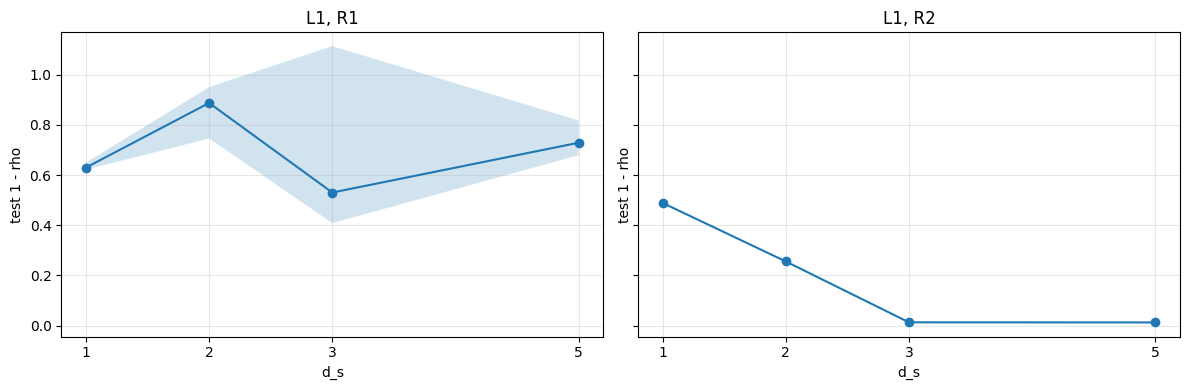

In [64]:
trend_variant('L1', 'nrmse_test')
trend_variant('L1', 'one_minus_rho_test')

## L2: affine map to the modes, $\bar y+\sum_{k=1}^{K}(W\mathbf{s}+\mathbf{b})_k\varphi_k$

The reconstructor (`build_L2`) is linear in the latents with trainable $W\in\mathbb{R}^{K\times d_s}$ and $\mathbf{b}\in\mathbb{R}^K$ ($K(d_s+1)$ parameters), on the fixed Fourier basis. The sweep is over $d_s$ and $K$.

In [42]:
sweep('L2')

L2: 156 runs to do, 0 already done
[1/156] L2_R1_ds1_K1_s0          train    0.2 s   test NRMSE 1.449e-01
[2/156] L2_R2_ds1_K1_s0          train    3.6 s   test NRMSE 1.449e-01
[3/156] L2_R1_ds1_K3_s0          train    0.3 s   test NRMSE 1.155e-01
[4/156] L2_R2_ds1_K3_s0          train    3.5 s   test NRMSE 9.546e-02
[5/156] L2_R1_ds1_K5_s0          train    0.3 s   test NRMSE 1.155e-01
[6/156] L2_R2_ds1_K5_s0          train    3.8 s   test NRMSE 9.547e-02
[7/156] L2_R1_ds1_K9_s0          train    0.3 s   test NRMSE 1.155e-01
[8/156] L2_R2_ds1_K9_s0          train    4.0 s   test NRMSE 9.542e-02
[9/156] L2_R1_ds1_K17_s0         train    0.4 s   test NRMSE 1.155e-01
[10/156] L2_R2_ds1_K17_s0         train    4.5 s   test NRMSE 9.551e-02
[11/156] L2_R1_ds1_K33_s0         train    0.6 s   test NRMSE 1.155e-01
[12/156] L2_R2_ds1_K33_s0         train    5.0 s   test NRMSE 9.548e-02
[13/156] L2_R1_ds1_K65_s0         train    0.7 s   test NRMSE 1.155e-01
[14/156] L2_R2_ds1_K65_s0         trai

### L2: comparison of the configurations

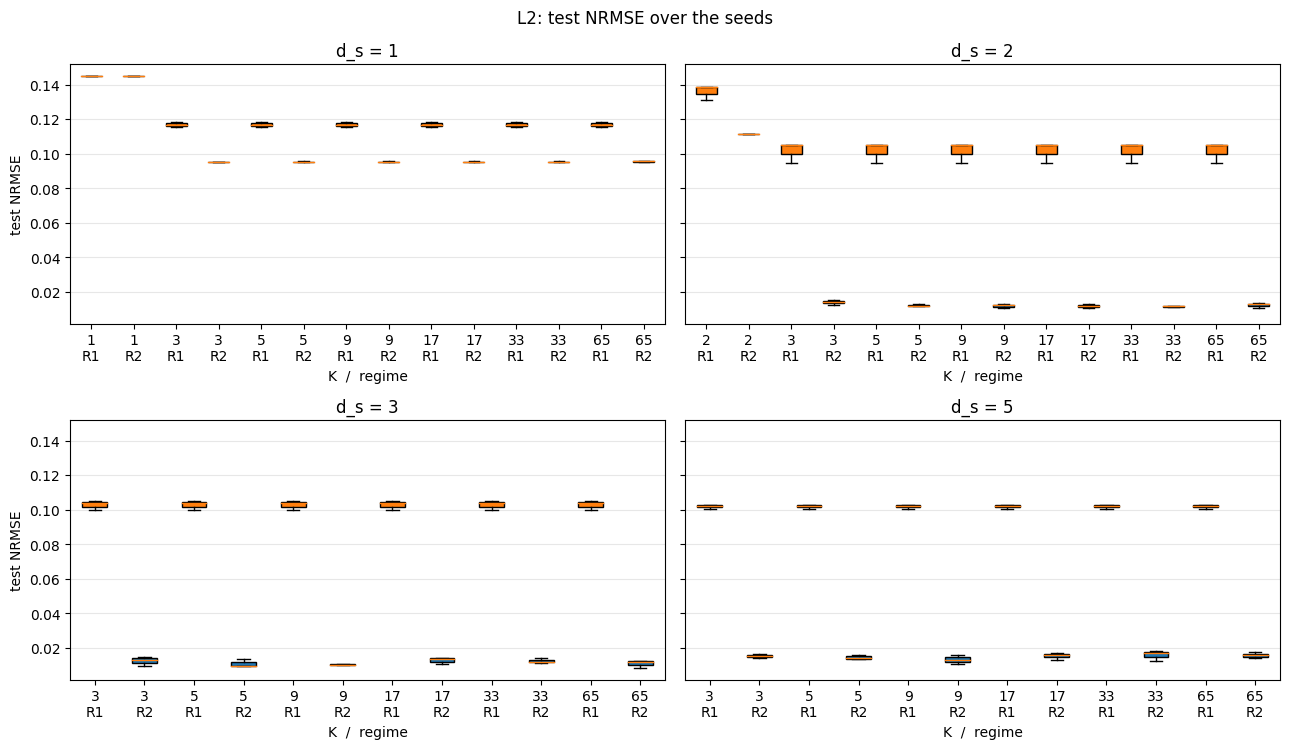

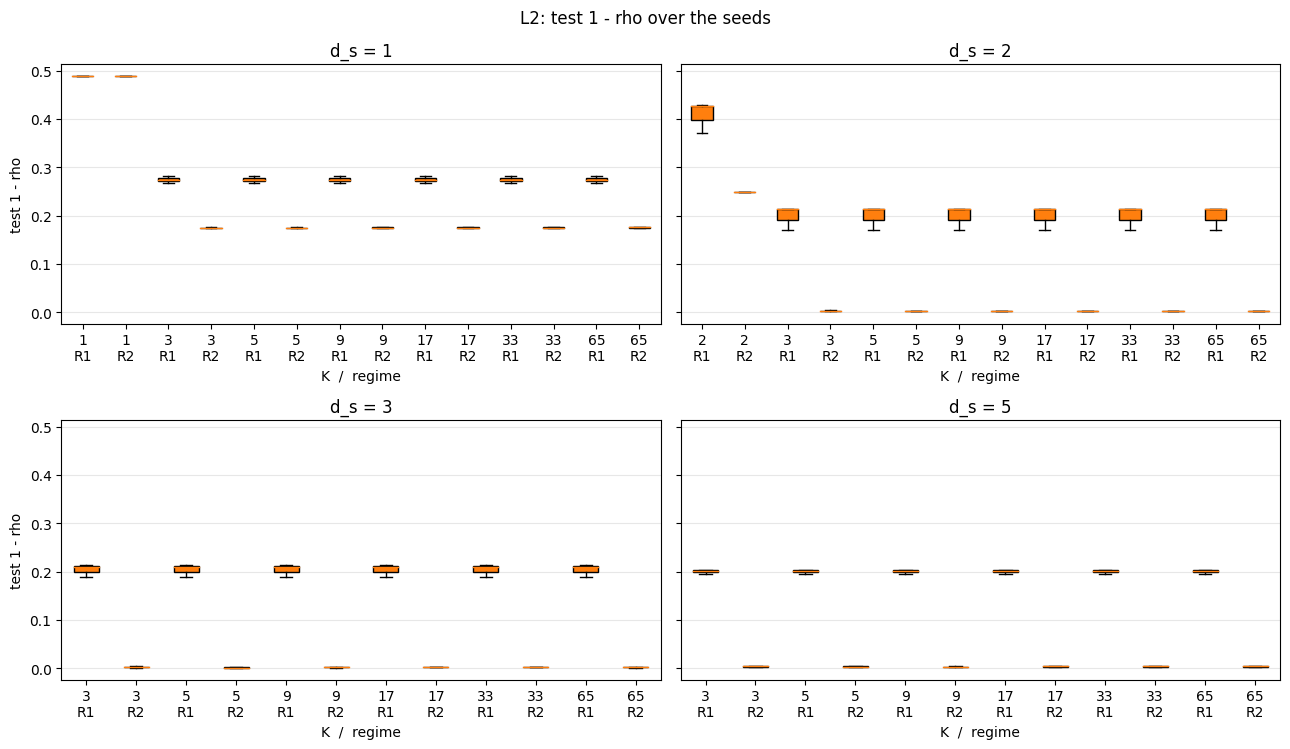

In [56]:
boxplot_variant('L2', 'nrmse_test')
boxplot_variant('L2', 'one_minus_rho_test')

### L2: trend with the dimensionality

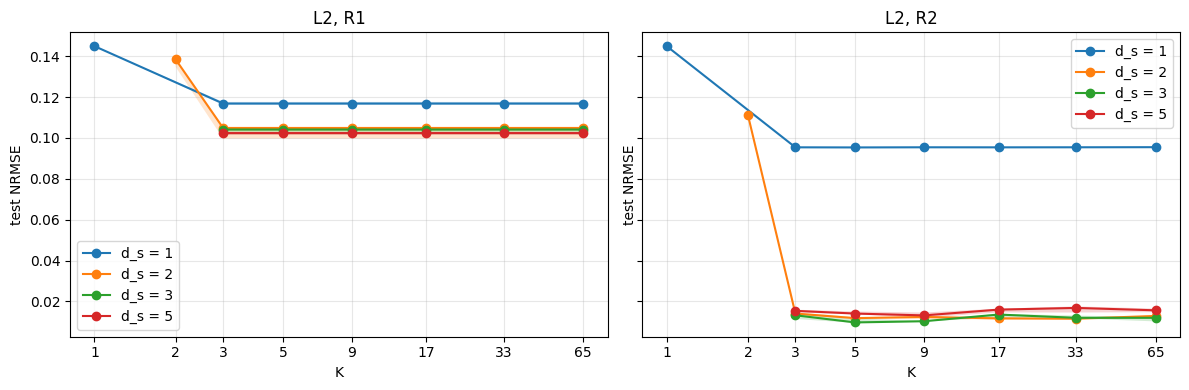

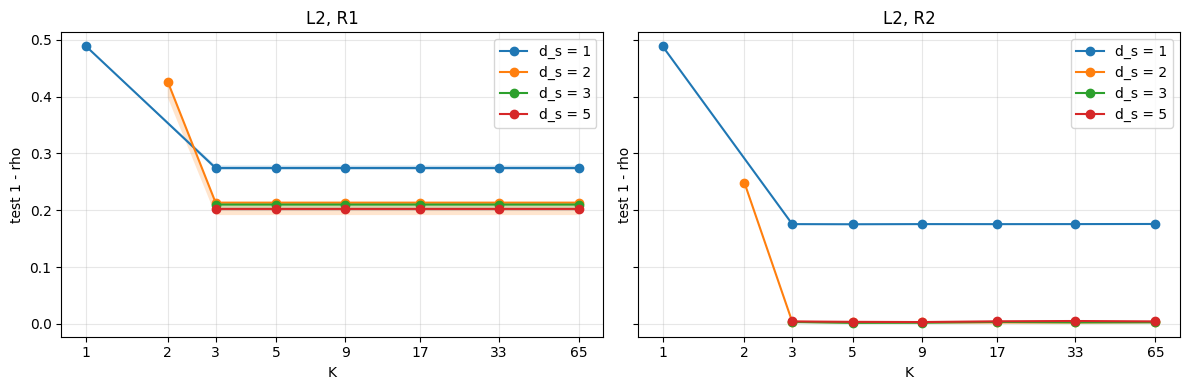

In [65]:
trend_variant('L2', 'nrmse_test')
trend_variant('L2', 'one_minus_rho_test')

## L3: nonlinear map to the modes, $\bar y+\sum_{k=1}^{K}g_\theta(\mathbf{s})_k\varphi_k$

$g_\theta:\mathbb{R}^{d_s}\to\mathbb{R}^K$ (`build_L3`) is a tanh MLP with two hidden layers whose width is the largest one with at most as many parameters as the L0 reconstructor (minimum 1), on the fixed Fourier basis.

**Caution when reading the trend with $K$:** the budget fixes the width, so it shrinks as $K$ grows (6-7 units at $K=3$, 3-4 at $K=17$, 1 from $K=33$ on; see `width` and `rec_params` in `runs.csv`). The large-$K$ points therefore mostly measure a bottleneck of the MLP, not of the basis; a best-size sweep (protocol Sec. 4) is the natural follow-up.

In [45]:
sweep('L3')

L3: 156 runs to do, 0 already done
[1/156] L3_R1_ds1_K1_s0          train    1.1 s   test NRMSE 1.449e-01
[2/156] L3_R2_ds1_K1_s0          train    4.1 s   test NRMSE 1.449e-01
[3/156] L3_R1_ds1_K3_s0          train    1.6 s   test NRMSE 8.063e-02
[4/156] L3_R2_ds1_K3_s0          train    4.7 s   test NRMSE 8.054e-02
[5/156] L3_R1_ds1_K5_s0          train    1.5 s   test NRMSE 7.998e-02
[6/156] L3_R2_ds1_K5_s0          train    4.3 s   test NRMSE 7.939e-02
[7/156] L3_R1_ds1_K9_s0          train    1.8 s   test NRMSE 7.987e-02
[8/156] L3_R2_ds1_K9_s0          train    4.2 s   test NRMSE 7.970e-02
[9/156] L3_R1_ds1_K17_s0         train    1.3 s   test NRMSE 8.642e-02
[10/156] L3_R2_ds1_K17_s0         train    4.8 s   test NRMSE 9.520e-02
[11/156] L3_R1_ds1_K33_s0         train    2.0 s   test NRMSE 1.072e-01
[12/156] L3_R2_ds1_K33_s0         train    5.6 s   test NRMSE 9.542e-02
[13/156] L3_R1_ds1_K65_s0         train    2.5 s   test NRMSE 1.072e-01
[14/156] L3_R2_ds1_K65_s0         trai

### L3: comparison of the configurations

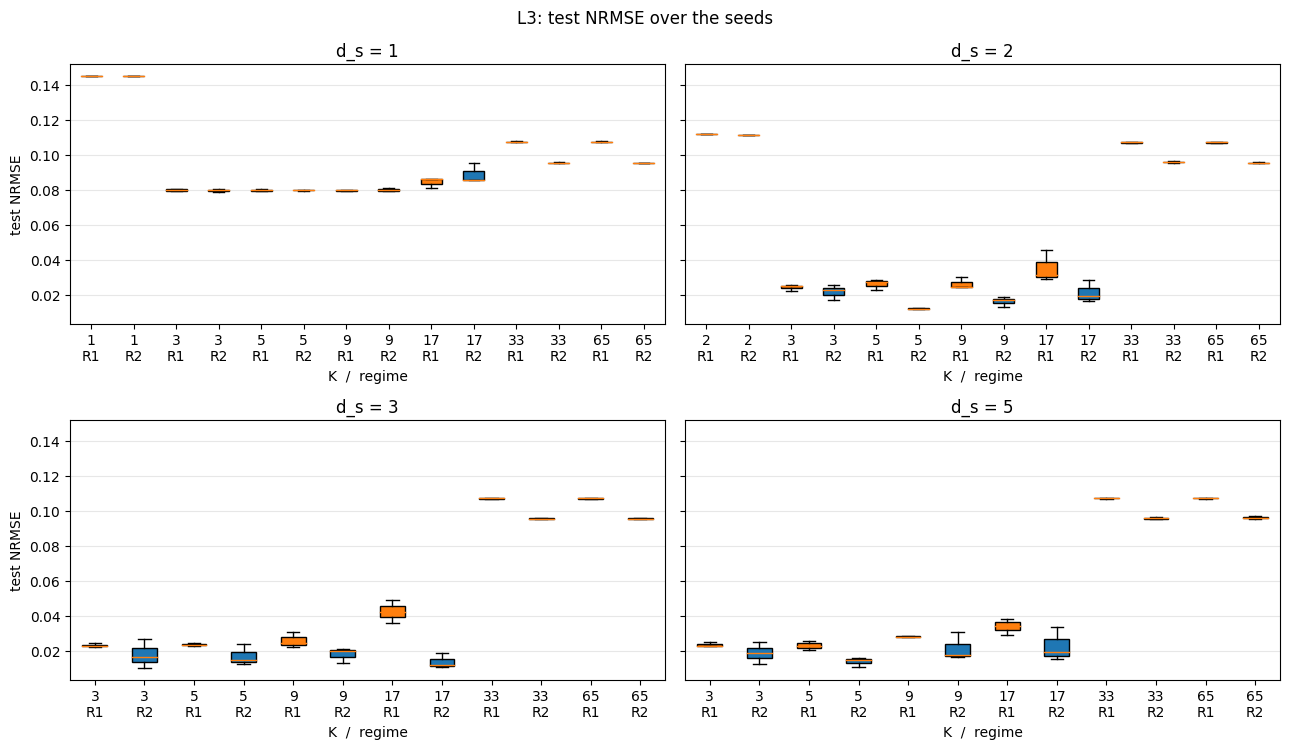

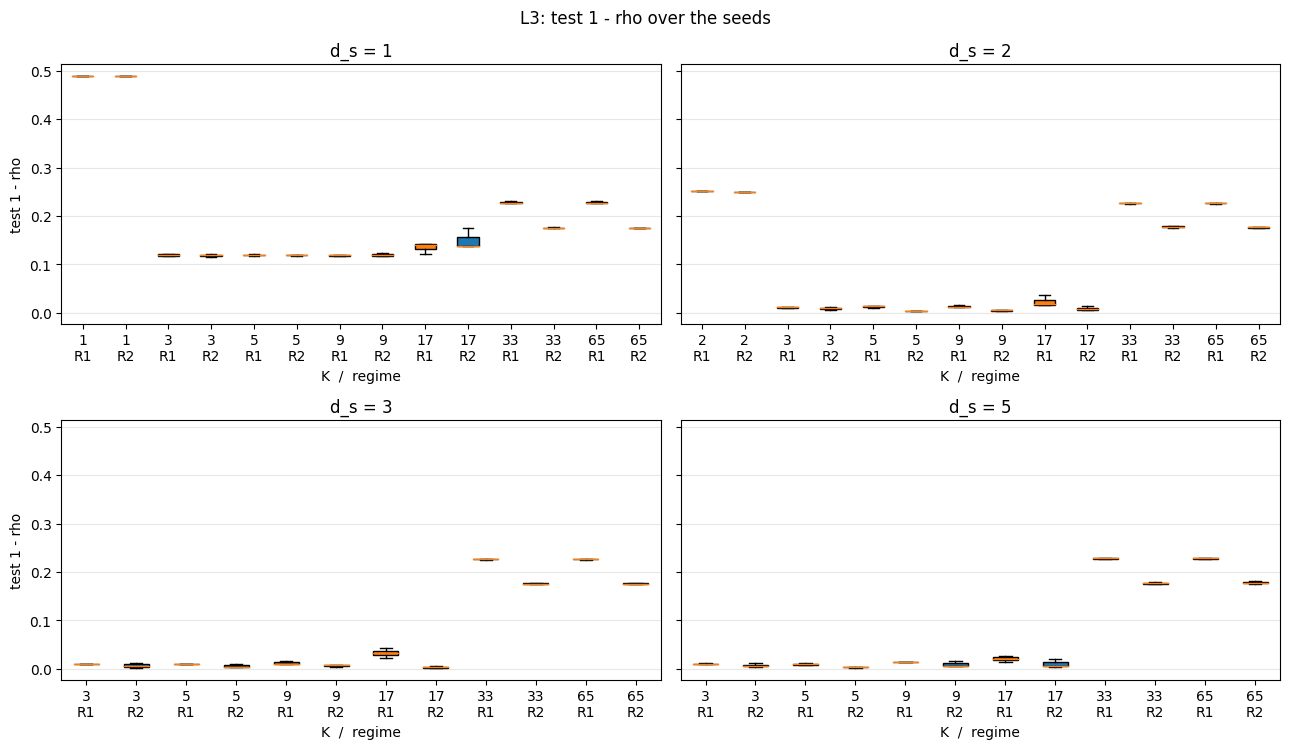

In [58]:
boxplot_variant('L3', 'nrmse_test')
boxplot_variant('L3', 'one_minus_rho_test')

### L3: trend with the dimensionality

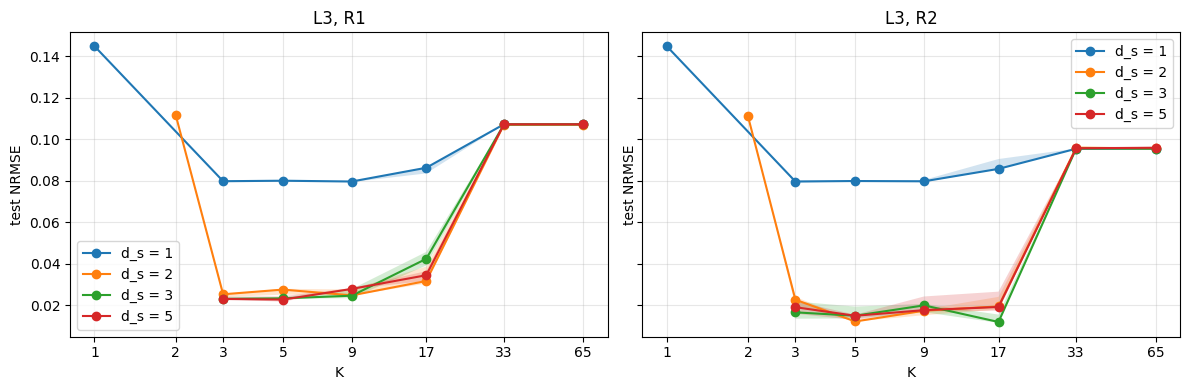

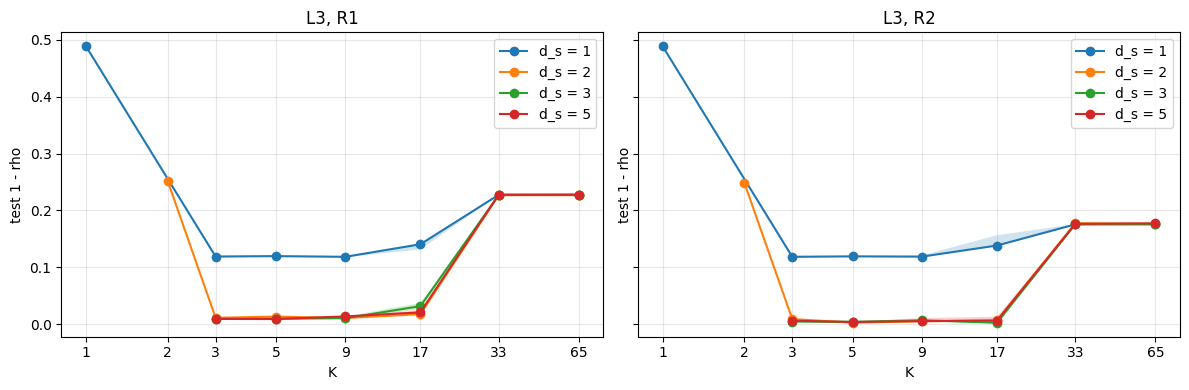

In [66]:
trend_variant('L3', 'nrmse_test')
trend_variant('L3', 'one_minus_rho_test')

## Final comparison: the best configuration of every procedure

A procedure is a variant with a regime (L0 appears once). Its **best configuration** is the $(d_s,K)$ with the lowest median validation NRMSE over the seeds: the test set is never used to choose (pass `select = 'nrmse_test'` to `best_configs` to choose on it instead). The table shows the medians over the seeds, then a boxplot over the seeds compares the procedures.

In [67]:
CONFIG = ['variant', 'regime', 'd_s', 'K']

def best_configs(select = 'nrmse_valid'):
    '''For every (variant, regime): the (d_s, K) with the lowest median `select` over the seeds.'''
    med = load('runs').groupby(CONFIG)[select].median().reset_index()
    return med.loc[med.groupby(['variant', 'regime'])[select].idxmin(), CONFIG]

best = best_configs()
best_runs = load('runs').merge(best, on = CONFIG)                           # all the seeds of the best configurations

columns = ['rec_params', 'nrmse_train', 'nrmse_test', 'one_minus_rho_train', 'one_minus_rho_test',
           'eps_total_test', 'eps_proj_test', 'eff_ratio_test', 'train_time_s', 'infer_time_s']
table = best_runs.groupby(CONFIG)[columns].median().reset_index()
table['rec_params'] = table['rec_params'].astype(int)
print(table.to_string(index = False, float_format = lambda v: '%1.3e' % v))

variant regime  d_s  K  rec_params  nrmse_train  nrmse_test  one_minus_rho_train  one_minus_rho_test  eps_total_test  eps_proj_test  eff_ratio_test  train_time_s  infer_time_s
     L0     R2    5  0         113    1.691e-02   2.264e-02            6.131e-03           9.046e-03       1.343e-01            NaN             NaN     1.431e+01     1.475e-02
     L1     R1    1  1           0    1.483e-01   1.678e-01            6.020e-01           6.295e-01       9.951e-01      8.596e-01       1.158e+00     0.000e+00     3.475e-04
     L1     R2    3  3           0    2.449e-02   2.848e-02            1.224e-02           1.354e-02       1.690e-01      5.660e-12       2.985e+10     3.793e+00     1.743e-03
     L2     R1    5  3          18    8.113e-02   1.024e-01            1.523e-01           2.023e-01       6.073e-01      5.660e-12       1.073e+11     4.837e-01     1.046e-03
     L2     R2    3  5          20    6.800e-03   9.715e-03            9.889e-04           1.646e-03       5.763e-02    

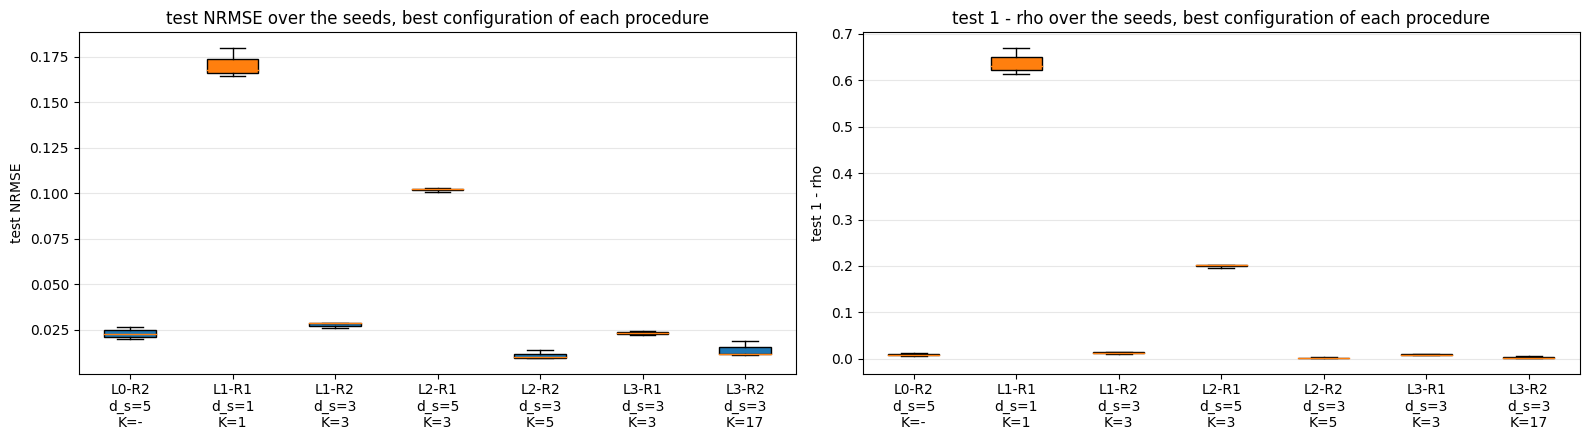

In [60]:
fig, axs = plt.subplots(1, 2, figsize = (16, 4.5))
groups = list(best_runs.groupby(CONFIG))
for ax, metric in zip(axs, ['nrmse_test', 'one_minus_rho_test']):
    bp = ax.boxplot([g[metric].values for _, g in groups], patch_artist = True,
                    labels = [f"{v}-{r}\nd_s={d}\nK={K if K else '-'}" for (v, r, d, K), _ in groups])
    for patch, ((v, r, d, K), _) in zip(bp['boxes'], groups):
        patch.set_facecolor(REGIME_COLOR[r])
    ax.set(ylabel = LABEL[metric], title = f'{LABEL[metric]} over the seeds, best configuration of each procedure')
    ax.grid(True, axis = 'y', alpha = 0.3)
fig.tight_layout()
plt.show()

### Predictions compared to the FOM

For every procedure, the seed with the lowest validation NRMSE of its best configuration, rebuilt from the saved weights (the check verifies that the rebuilt model gives the stored test NRMSE). FOM on the left, reduced model on the right, as in the original notebook.

L0-R2: d_s = 5, K = -, seed 1, test NRMSE 1.963e-02


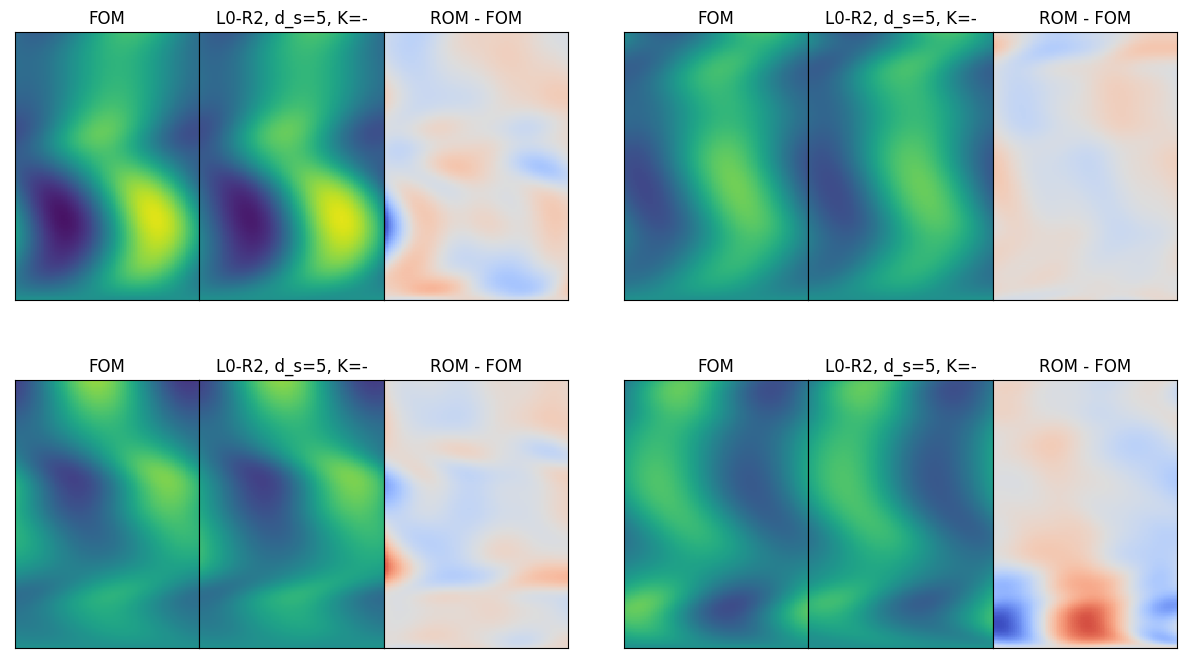

L1-R1: d_s = 1, K = 1, seed 0, test NRMSE 1.641e-01


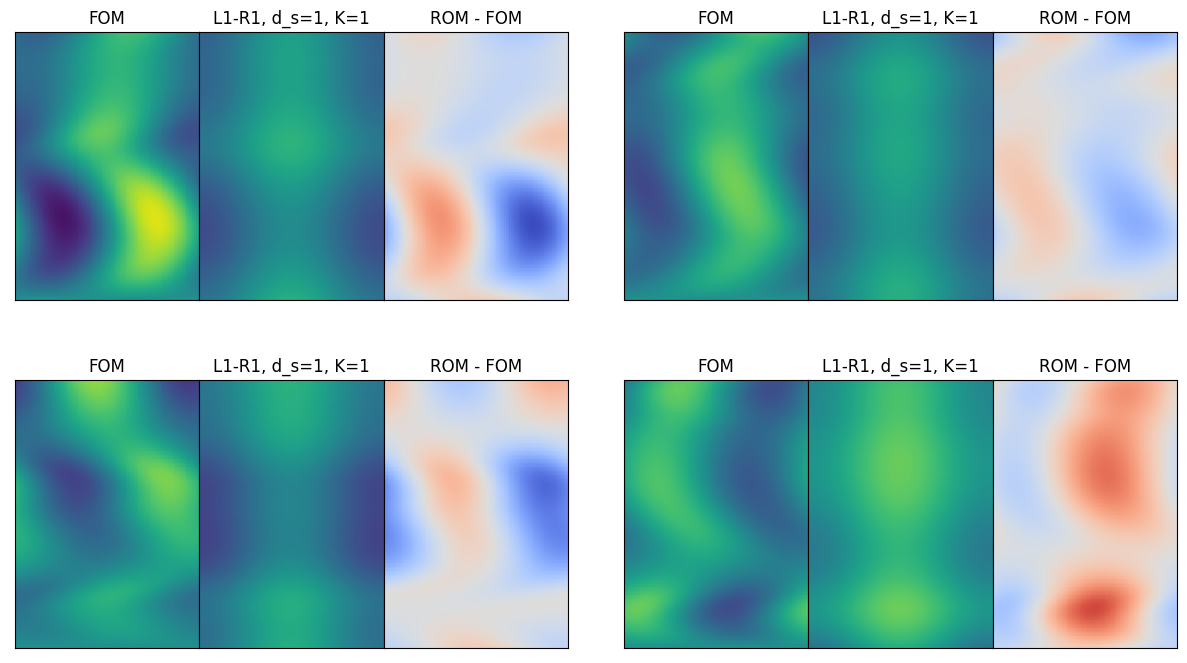

L1-R2: d_s = 3, K = 3, seed 2, test NRMSE 2.565e-02


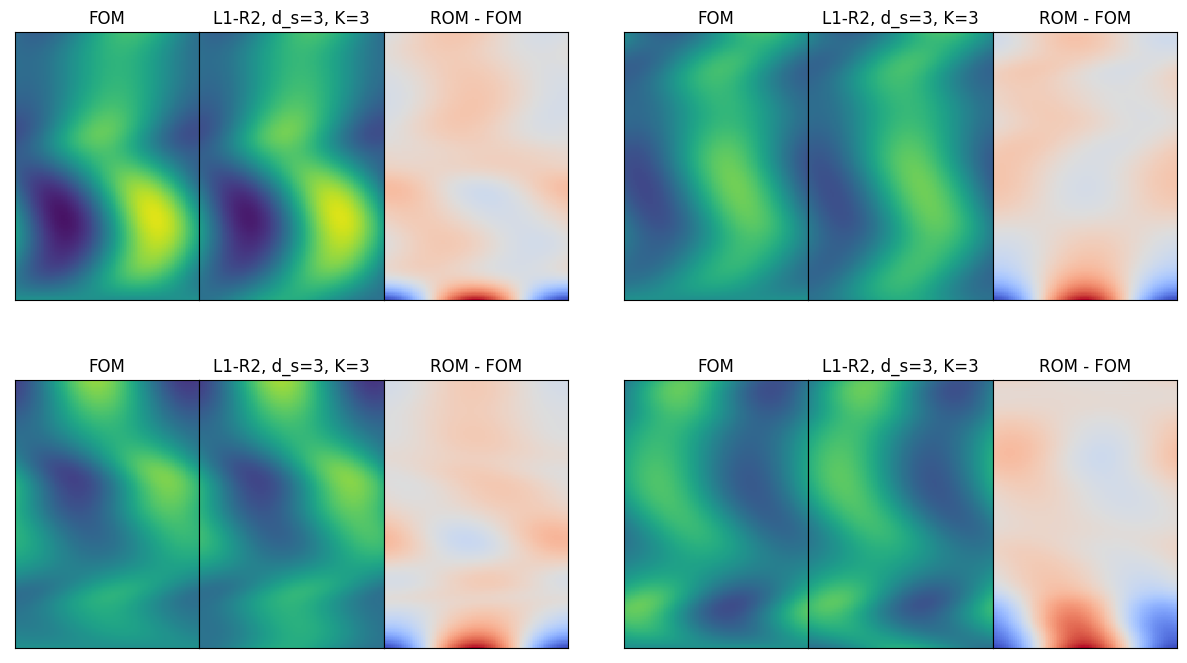

L2-R1: d_s = 5, K = 3, seed 2, test NRMSE 1.006e-01


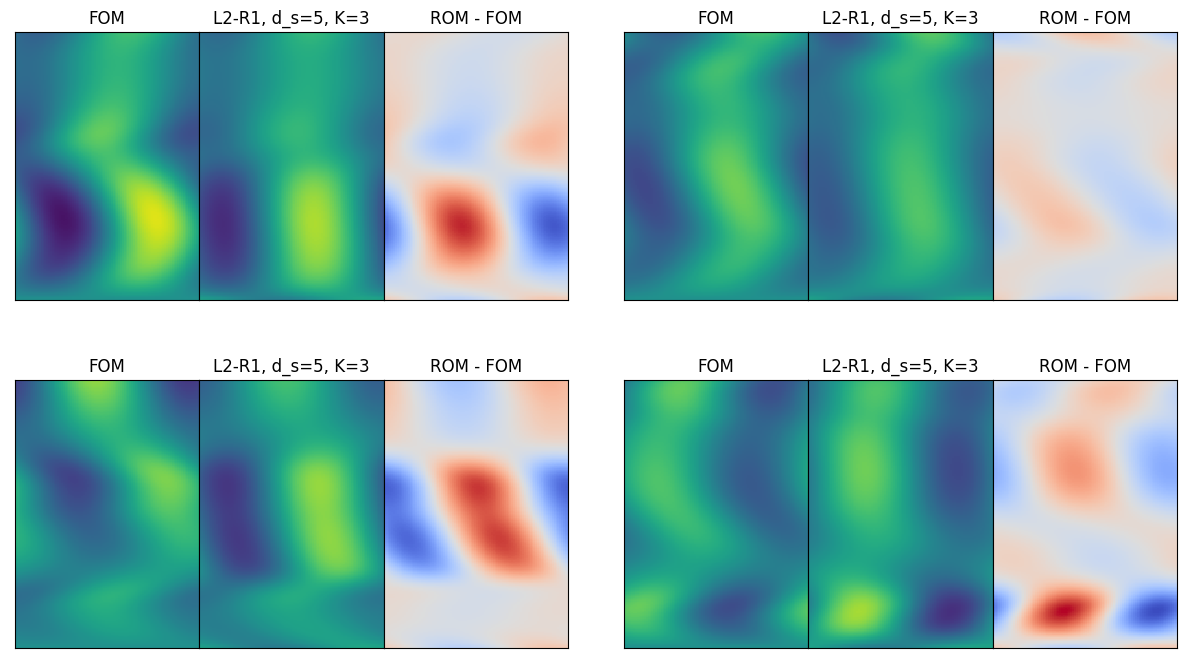

L2-R2: d_s = 3, K = 5, seed 2, test NRMSE 9.715e-03


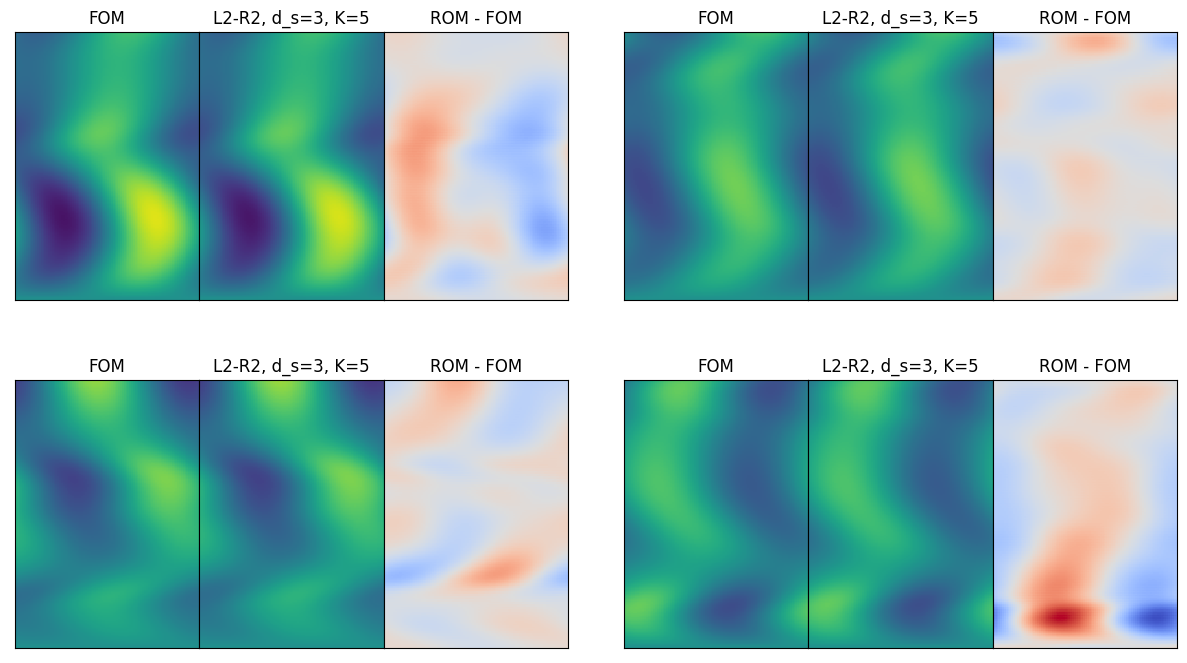

L3-R1: d_s = 3, K = 3, seed 0, test NRMSE 2.228e-02


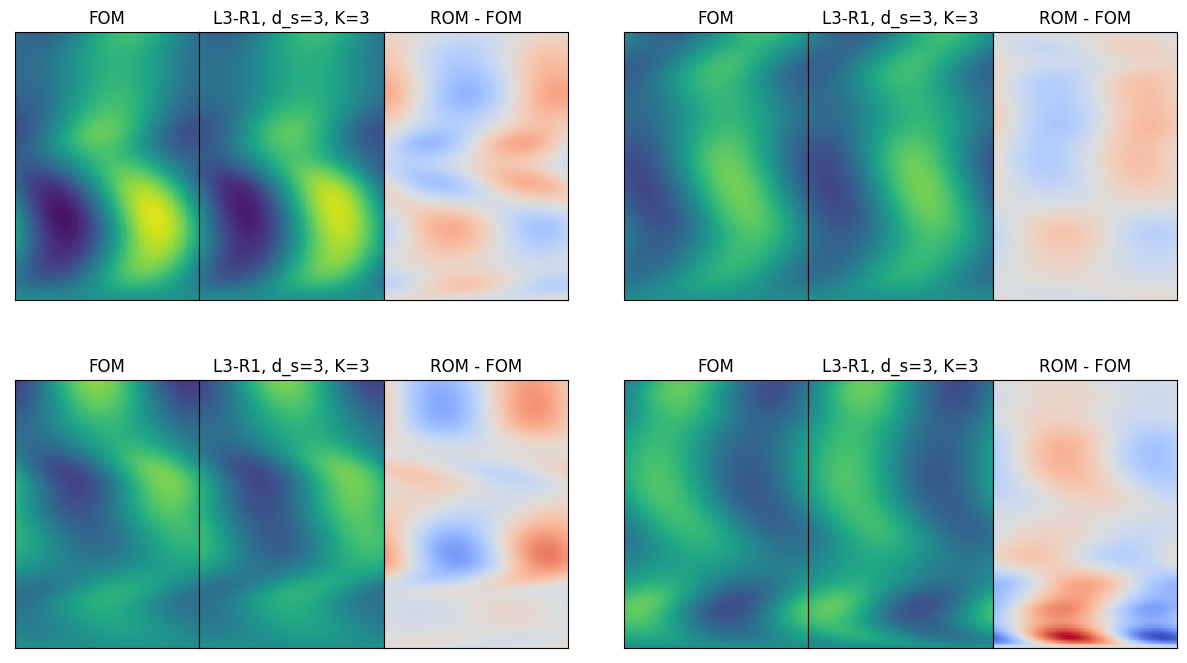

L3-R2: d_s = 3, K = 17, seed 1, test NRMSE 1.183e-02


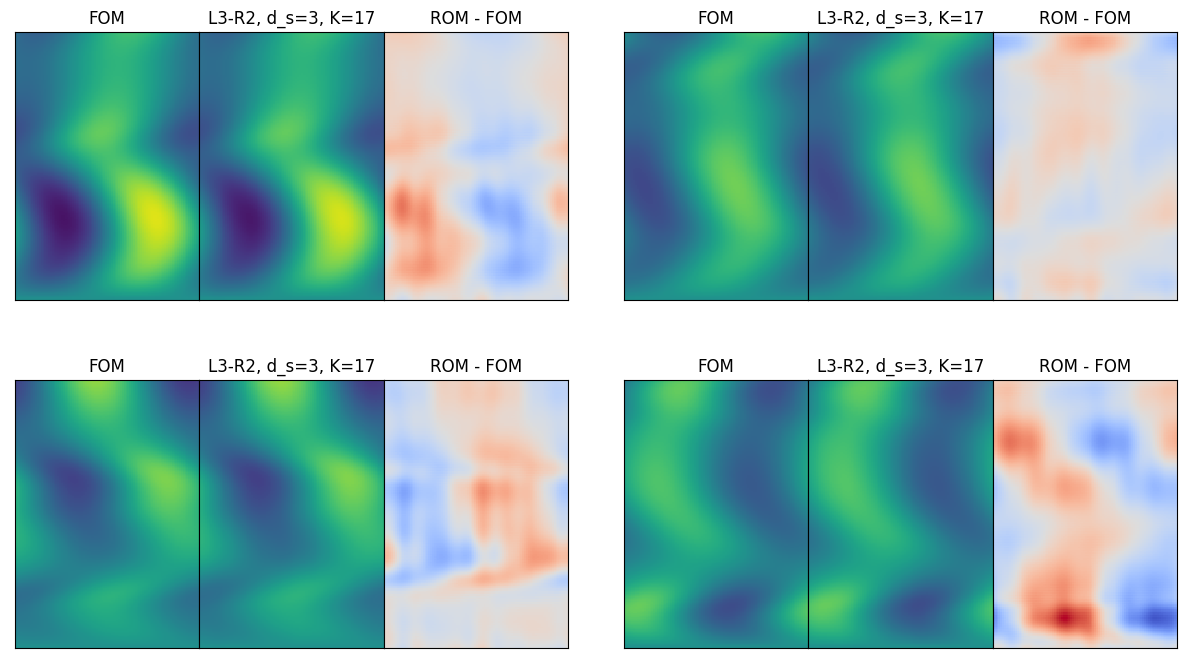

In [68]:
def plot_output_1D_error(dataset, out_fields_ref, out_fields_app, n_row, n_col, title_ROM = 'ROM'):
    '''utils.plot_output_1D plus a third panel per sample: the pointwise error ROM - FOM, on a shared symmetric colour scale.'''
    fig = plt.figure(figsize = (15, 8), constrained_layout = False)
    outer_grid = fig.add_gridspec(n_row, n_col, wspace = 1e-1, hspace = 3e-1)

    t = dataset['times']
    x = dataset['points']
    X, T = np.meshgrid(x, t)

    err = out_fields_app - out_fields_ref
    vmin, vmax = np.min(out_fields_ref), np.max(out_fields_ref)
    elim = np.max(np.abs(err[:n_row*n_col]))
    for i_sample in range(n_col*n_row):
        idx_col = i_sample % n_col
        idx_row = int((i_sample - idx_col) / n_col)

        inner_grid = outer_grid[idx_row, idx_col].subgridspec(1, 3, wspace = 0, hspace = 0)
        axs = inner_grid.subplots()

        axs[0].pcolormesh(X, T, out_fields_ref[i_sample,:,:,0], shading = 'auto', vmin = vmin, vmax = vmax)
        axs[1].pcolormesh(X, T, out_fields_app[i_sample,:,:,0], shading = 'auto', vmin = vmin, vmax = vmax)
        axs[2].pcolormesh(X, T, err[i_sample,:,:,0], shading = 'auto', vmin = -elim, vmax = elim, cmap = 'coolwarm')
        axs[0].set_title('FOM')
        axs[1].set_title(title_ROM)
        axs[2].set_title('ROM - FOM')

        for ax in axs.flatten():
            ax.set(xticks = [], yticks = [])
            for spine in ['top', 'bottom', 'left', 'right']: ax.spines[spine].set_visible(True)
    return fig

for (variant, regime, d_s, K), g in best_runs.groupby(CONFIG):
    best_run = g.loc[g.nrmse_valid.idxmin()]
    pred = predict_test(variant, regime, d_s, K, int(best_run.seed))
    print(f'{variant}-{regime}: d_s = {d_s}, K = {K if K else "-"}, seed {int(best_run.seed)}, test NRMSE {best_run.nrmse_test:.3e}')
    assert np.isclose(nrmse_rho(pred, REF['test'])[0], best_run.nrmse_test, rtol = 1e-6), 'rebuilt model does not match the stored result'
    plot_output_1D_error(dataset_tests, REF['test'], pred, 2, 2, title_ROM = f'{variant}-{regime}, d_s={d_s}, K={K if K else "-"}')
    plt.show()